In [1]:
!pip install pymysql sqlalchemy pandas

In [3]:
import pandas as pd
from sqlalchemy import create_engine

# 1. Load the raw dataset
df = pd.read_csv('customer_churn.csv')

# 2. Clean TotalCharges and SeniorCitizen
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print(f"Data cleaned. Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# 3. Connection details for your XAMPP MySQL (Port 3307)
username = 'root'
password = ''
host = '127.0.0.1'
port = '3307'
database = 'telco_churn_db'

connection_str = f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}"
engine = create_engine(connection_str)

# 4. Push directly into MySQL
df.to_sql('customers', con=engine, if_exists='replace', index=False)
print("Data imported into 'customers' table in MySQL successfully!")

Data cleaned. Rows: 7043, Columns: 21
Data imported into 'customers' table in MySQL successfully!


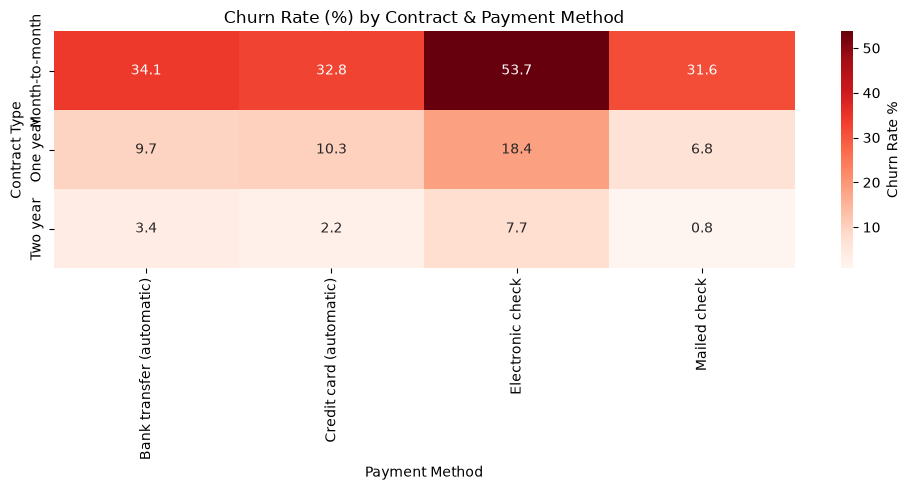

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# SQL se direct aggregated data fetch karo
query = """
SELECT 
    Contract,
    PaymentMethod,
    ROUND((SUM(CASE WHEN Churn = 'Yes' THEN 1.0 ELSE 0.0 END) / COUNT(*)) * 100, 2) AS churn_rate_pct
FROM customers
GROUP BY Contract, PaymentMethod
ORDER BY churn_rate_pct DESC;
"""

churn_cohort = pd.read_sql(query, con=engine)

# Heatmap Plot karo
pivot_table = churn_cohort.pivot(index='Contract', columns='PaymentMethod', values='churn_rate_pct')

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="Reds", cbar_kws={'label': 'Churn Rate %'})
plt.title('Churn Rate (%) by Contract & Payment Method')
plt.ylabel('Contract Type')
plt.xlabel('Payment Method')
plt.tight_layout()
plt.savefig('churn_risk_heatmap.png', dpi=300)
plt.show()

In [5]:
from scipy.stats import chi2_contingency, ttest_ind

# 1. Chi-Square Test: Payment Method vs Churn
contingency_table = pd.crosstab(df['PaymentMethod'], df['Churn'])
chi2, p_val, dof, _ = chi2_contingency(contingency_table)
print(f"Chi-Square Test (Payment Method vs Churn): Chi2 = {chi2:.2f}, p-value = {p_val:.4e}")

# 2. T-Test: Monthly Charges for Churned vs Non-Churned
churn_charges = df[df['Churn'] == 'Yes']['MonthlyCharges']
stay_charges = df[df['Churn'] == 'No']['MonthlyCharges']
t_stat, p_val_ttest = ttest_ind(churn_charges, stay_charges, equal_var=False)
print(f"T-Test (Monthly Charges): t-stat = {t_stat:.2f}, p-value = {p_val_ttest:.4e}")

Chi-Square Test (Payment Method vs Churn): Chi2 = 648.14, p-value = 3.6824e-140
T-Test (Monthly Charges): t-stat = 18.41, p-value = 8.5924e-73
